# Labjournaal BM
## General
Template for labjournaal. See https://jupyter-notebook.readthedocs.io/en/stable/examples/Notebook/Working%20With%20Markdown%20Cells.html for options to use markdown.

**Name: Koen van der Heide**  
**Title of the experiment:**  
**Starting date:**  
**Expected enddate:**  
**Partner:**  
**Goal of the experiment:**  
**Research question:**  
**Expectations or Hypothesis:**  
**Desired accuracy:  $1.380649\cdot10^{−23}\mathrm{J/K}$**  




In [1]:
#import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit 
from scipy.constants import Boltzmann as K_B

# Preparation
 


**Assignments:**  

**Method:**  
**Theory:**  
**Independent variable:**  
**Dependent variable:**  
**Controlled variablen:**  
**Measurement instruments \& Settings:**  
**Procedure:**  
**Setup(drawing or picture):**  
**Notes:**  
**About accuracy:**  


# Execution

In [2]:
# Measurements: Explain the names of variables provide only raw data in np.arrays!
#Ruwe data
Ruw_U_R1=np.array([0.011,0.034,0.099,0.204,0.367,0.606,0.765,0.956,1.180,1.453,1.773,2.594,4.457,5.299,6.240,8.630,11.684,20.939,29.430,32.875,58.750,79.943,116.073,149.275,184.470,221.16,259.04,297.78,337.64,377.67,418.34,459.48,501.03,676.76])
Ruw_U_bron=np.array([0.09,0.19,0.39,0.59,0.79,0.99,1.09,1.19,1.29,1.4,1.49,1.69,1.99,2.09,2.19,2.39,2.59,2.98,3.285,3.39,3.98,4.38,4.98,5.48,5.98,6.48,6.98, 7.48,7.98,8.47,8.97,9.47,10.00,12.08])



# Processing
**Description of processing of raw data into scientific evidence:**


In [53]:
#Bewerkte data
# Functies voor het berekenen van de onzekerheden
def vijfhalf(x):
    for i in range(len(U_R1)):
        if U_R1[i]<= 0.2:                                            #Er zijn 2 instellingen gebruit voor het meten van de spanning van de spanningsmeter vijfhalf.
            afstelling = 0.2 #Volt
            percentage = 0.004
        if U_R1[i]>= 0.2:                
            afstelling = 2     #Volt
            percentage = 0.003    
    return 0.015*10**-2 *x +percentage*10**-2*afstelling     
def driehalf(x):
    afstelling = 40 #Volt
    return 0.7*10**-2 * x+0.01*10**-2*afstelling               #0.7%*aflezing + 0.01%*afstelling
def vijfhalf_weerstand(x):
    afstelling = 2 # K.Ohm
    return 0.02*10**-2*x+0.003*10**-2*afstelling                   #0.02%*x+0.003%*afstelling

#Gemeten weerstanden
R1=33.149*10**3                          #33 K.Ohm 
Onzekerheid_R1=vijfhalf_weerstand(R1)+0.2 #Ohm wegens gebruik gemaakt van perform 2-wire. 
R2= 0.99466*10**3                        #1 K.Ohm
Onzekerheid_R2=vijfhalf_weerstand(R2)+0.2
R3=100.440                               #100 Ohm
Onzekerheid_R3=vijfhalf_weerstand(R3)+0.2

#Constantes
q=-1.6022e-19
Onzekerheid_q = 0                                 #Dit hebben we aangenomen
n=2
Onzekerheid_n=0.1

Temperatuur_in_celsius=19
Kelvin_bijnulgraden=273.15
T= Kelvin_bijnulgraden+ Temperatuur_in_celsius
Onzekerheid_T=2.0

#Aanpassingen van ruwe data
U_R1=Ruw_U_R1*10**-3
Verhouding = R3/(R2+R3)
U_bron = Ruw_U_bron*Verhouding



#Partieel gedoe
Onzekerheid_Ubron = driehalf(Ruw_U_bron)
Onzekerheid_U1= vijfhalf(U_R1)


#Voltage over de diode
U_D=U_bron-U_R1





#Onzekerheid klopt volgens mij
Onzekerheid_UD = np.sqrt((Onzekerheid_R2*(R3)/((R2+R3)**2)*U_bron)**2+(Onzekerheid_R3*(R2)/((R2+R3)**2)*U_bron)**2+(Onzekerheid_Ubron *(R3/(R2+R3)))**2+(Onzekerheid_U1)**2) #Onzekerheid door de

#Stroomsterkte door de diode
I_D=U_R1/R1
Onzekerheid_ID = I_D*np.sqrt(((Onzekerheid_U1/U_R1)**2)+((Onzekerheid_R1/R1)**2))


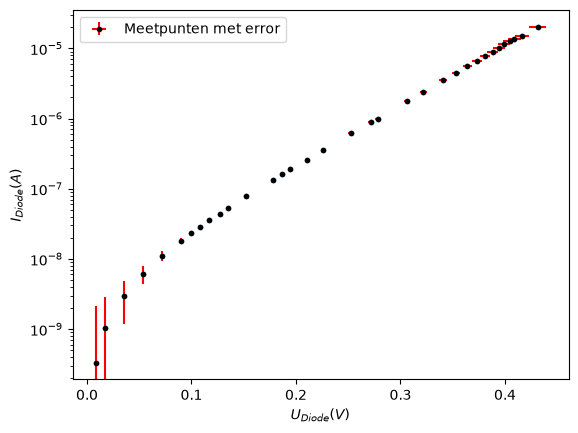

In [55]:
#Plot
xerr= Onzekerheid_UD
yerr= Onzekerheid_ID
plt.figure
plt.plot(U_D,I_D,'.')
plt.errorbar(U_D,I_D,fmt = 'k.',xerr=xerr,yerr=yerr,ecolor = 'r',label = 'Meetpunten met error')
plt.xlabel('$U_{Diode} (V)$')
plt.ylabel('$I_{Diode} (A)$')
plt.yscale('log')          
plt.legend()


#Opslaan grafiek
plt.savefig("punten.png", dpi=400, bbox_inches="tight")

**Describing the pattern in the processed data:**  


Constante van boltzmann is 1.36e-23 +/- 0.07e-23 J/K
De werkelijke constante is 1.380649e-23 J/K


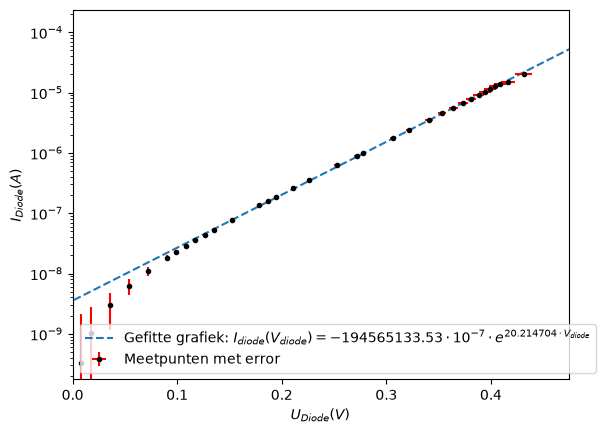

In [56]:
#Calculations of e.a. measurement uncertainties, and providing final answers.
#De fitfunctie: Hierbij is c gelijk aan I0 en de b is gelijk aan -q/(n*k_B*T).
def functie(x,b,c):
    return b*x+c           #Het lineaniseren van de punten

#Het bepalen
values,covariances=curve_fit(functie, U_D[U_D>0.1],np.log(I_D[U_D>0.1])) #U_D moet groter zijn dan 0.1 omdat vanaf 0.1 Volt er een lineaire lijn te bepalen is volgens de fitfunctie 
helling_b=values[0]
Onzekerheid_b=np.sqrt(covariances[0,0])
afsnede_c=values[1]
Onzekerheid_a=np.sqrt(covariances[1,1]) #deze waarde is niet zo belangrijk voor het bepalen van de constante van Boltzmann


#testlijn maken
x_test = np.linspace(-1*min(U_D),1.2*max(U_D),1000)
y_test = np.e**(functie(x_test,values[0],values[1]))
plt.plot(x_test,y_test,'--', label='Gefitte grafiek: $ I_{diode}(V_{diode}) = %.2f\\cdot10^{-7} \\cdot e^{%f \\cdot V_{diode}} $' %(values[1]*10**7,values[0]))
plt.xlim(0,1.1*max(U_D))

#Originele grafiek met errorbars plotten
plt.xlabel('$U_{Diode} (V)$')
plt.ylabel('$I_{Diode} (A)$')
plt.errorbar(U_D,I_D,fmt = 'k.',xerr=xerr,yerr=yerr,ecolor = 'r',label = 'Meetpunten met error')
plt.legend()
plt.yscale('log')
#Boltzmann berekenen
k_B =-q/(helling_b*n*T)
Onzekerheid_k_B=k_B*np.sqrt((Onzekerheid_b/helling_b)**2+(Onzekerheid_n/n)**2+(Onzekerheid_T/T)**2)
print('Constante van boltzmann is %.2e +/- %.2fe-23 J/K'%(k_B,Onzekerheid_k_B*10**23))
print('De werkelijke constante is',K_B,  'J/K')

#Opslaan grafiek
plt.savefig("punten met een gefitte lijn.png", dpi=400, bbox_inches="tight")

Jouw waarde is niet strijdig met de constante van Boltzmann.


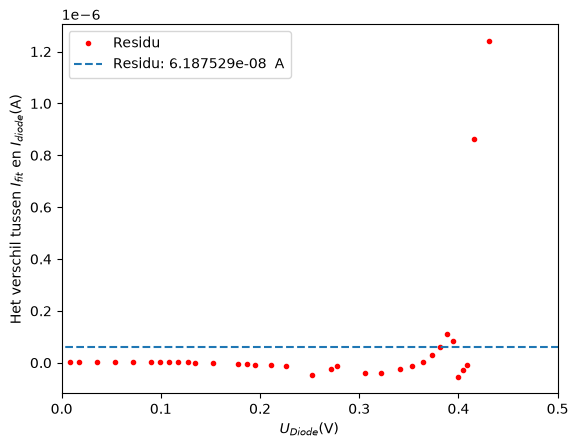

In [57]:
#Residual
Waardes= np.e**functie(U_D,values[0],values[1])
Residual =Waardes-I_D
Residu_gem=np.mean(Residual)

#een plot maken van de residu
lijnx=np.array([-1,0.60])
lijny=np.array([Residu_gem,Residu_gem])
plt.plot(U_D,Residual, 'r.', label ='Residu')
plt.xlabel('$U_{Diode}(\\mathrm{V})$')
plt.ylabel('Het verschil tussen $I_{fit}$ en $I_{diode}( \\mathrm{A}$)')
plt.plot(lijnx,lijny,'--',label = 'Residu: %e $\\; \\mathrm{A}$'%(Residu_gem))
plt.xlim(0,0.5)
plt.legend(loc='best')
plt.figure

#Strijdigheidsanalyse
Onzekerheid_echte_k_B=0
if abs(K_B-k_B)>=2*np.sqrt(Onzekerheid_k_B**2+Onzekerheid_echte_k_B**2):
    print('Jouw waarde is strijdig met de constante van Boltzmann')
else:
    print('Jouw waarde is niet strijdig met de constante van Boltzmann.')

#Opslaan grafiek
plt.savefig("Residual.png", dpi=400, bbox_inches="tight")

# Discussion



# Conclusion

# Additional notes, remarks, explanations, thoughts etc